# Knowledge graphs: a hands-on tutorial

A **knowledge graph (KG)** stores facts as a network: *things* are nodes, *relationships* are labelled,
directed edges. This notebook builds small KGs step by step and draws each one:

1. Facts as triples, and the graph they form
2. Querying: one-hop lookups, patterns, multi-hop paths
3. Schema: the types and relations a graph uses
4. Building a KG from text (and what goes wrong)
5. Entity resolution: merging duplicates, and wrong merges
6. Multi-hop question answering with provenance
7. Personalized PageRank, the retrieval trick behind HippoRAG
8. A real LLM-built graph: structure at scale

The examples are physics, matching the project this notebook lives in (KG-RAG vs. plain retrieval on
physics Wikipedia, see `RESEARCH_PROPOSAL.md`). Everything runs on CPU in a few seconds; only
`networkx` and `matplotlib` are needed.

In [1]:
import re
import textwrap
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

plt.rcParams["figure.dpi"] = 110

# One colour per entity type, used in every drawing (light colours so black labels stay readable).
TYPE_COLORS = {"Person": "#9ecae1", "Law/Theory": "#fdae6b", "Quantity": "#a1d99b",
               "Constant": "#fc9272", "Prize": "#bcbddc", "Unknown": "#d9d9d9"}
EXTRA = ["#c7e9c0", "#fdd0a2", "#dadaeb", "#c6dbef", "#fcbba1", "#e5f5e0", "#f2f0f7", "#fee6ce"]


# Hand-placed positions for every entity in the toy examples: gravity on top, motion in the
# middle, quantum at the bottom; people on the left. Names from text extraction share spots.
POS = {
    "Albert Einstein": (0, 8), "General relativity": (3, 8), "Newton's law of gravitation": (6, 8),
    "Johannes Kepler": (0, 6.5), "Kepler's laws": (3, 6.5),
    "Law of universal gravitation": (6, 6.5), "law of universal gravitation": (6, 6.5),
    "Gravitational constant": (9, 6.5), "gravitational constant": (9, 6.5),
    "Isaac Newton": (0, 4.5), "Newton": (0, 3), "Newton's laws of motion": (3, 3),
    "Force": (6, 4.5), "force": (6, 4.5), "newton": (9, 4.5),
    "Mass": (6, 3), "mass": (6, 3), "Acceleration": (6, 1.5), "acceleration": (6, 1.5),
    "Erwin Schrödinger": (0, 0), "Schrödinger equation": (3, 0), "Planck constant": (6, 0),
    "Schrödinger": (0, -1.8), "1933 Nobel Prize in Physics": (3, -1.8),
    "1918 Nobel Prize in Physics": (6, -1.8), "Max Planck": (9, -0.9),
}


def color_of(t):
    if t not in TYPE_COLORS:                      # unseen types get the next spare colour
        TYPE_COLORS[t] = EXTRA[(len(TYPE_COLORS) - 6) % len(EXTRA)]
    return TYPE_COLORS[t]


def draw_kg(G, ax=None, title=None, path=None, values=None, edge_label="relation", seed=7, k=None,
            node_size=1900, font_size=8, legend=True, pos=None):
    # Draw a (small) KG: nodes coloured by their "type" attribute (or by `values`, e.g. PageRank),
    # edges labelled with their relation; `path` (list of nodes) is highlighted in red.
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 8))
    if pos is None:     # toy graphs: fixed hand-placed positions (same spot in every figure)
        pos = {n: POS[n] for n in G} if all(n in POS for n in G) else nx.spring_layout(G, seed=seed, k=k)
    if values is not None:
        nodes = nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[values.get(n, 0) for n in G],
                                       cmap="YlOrRd", node_size=node_size, edgecolors="#555")
        plt.colorbar(nodes, ax=ax, shrink=0.6, label="score")
    else:
        nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, edgecolors="#555",
                               node_color=[color_of(G.nodes[n].get("type", "Unknown")) for n in G])
    on_path = set()
    if path:
        on_path = {e for a, b in zip(path, path[1:]) for e in ((a, b), (b, a))}
    arrows = dict(arrows=True, arrowsize=15) if G.is_directed() else dict(arrows=False)
    nx.draw_networkx_edges(G, pos, ax=ax, node_size=node_size, **arrows,
                           edge_color=["#d62728" if e in on_path else ("#cccccc" if path else "#666666")
                                       for e in G.edges()],
                           width=[3.5 if e in on_path else 1.3 for e in G.edges()])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=font_size,
                            labels={n: textwrap.fill(str(n), 14) + ("\n" + G.nodes[n]["note"] if "note" in G.nodes[n] else "")
                                    for n in G})
    if edge_label:
        nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=font_size - 1, font_color="#333",
                                     edge_labels={(u, v): d.get(edge_label, "") for u, v, d in G.edges(data=True)},
                                     bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    if legend and values is None:
        types = sorted({G.nodes[n].get("type", "Unknown") for n in G})
        ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=10, mfc=color_of(t), mec="#555", label=t)
                           for t in types], loc="lower left", fontsize=8, frameon=False)
    ax.set_title(title or "", fontsize=11)
    ax.margins(0.08)
    ax.axis("off")
    return pos

## 1. Facts as triples

The atomic unit of a KG is a **triple** `(head, relation, tail)`, also called *(subject, predicate, object)*:

> (Isaac Newton, **formulated**, Law of universal gravitation)

A set of triples *is* a graph: every distinct head or tail becomes a node, every triple a directed edge
labelled with its relation. Nodes can carry attributes. The most useful is a **type** (Person, Law, ...).

16 nodes, 14 edges


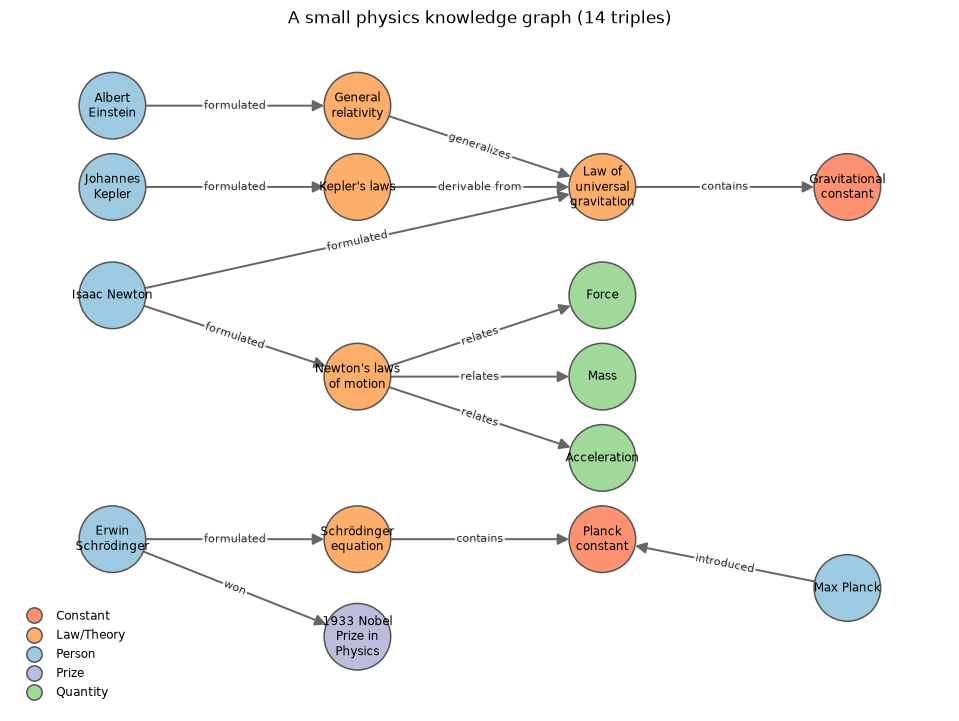

In [2]:
triples = [
    ("Isaac Newton", "formulated", "Newton's laws of motion"),
    ("Isaac Newton", "formulated", "Law of universal gravitation"),
    ("Newton's laws of motion", "relates", "Force"),
    ("Newton's laws of motion", "relates", "Mass"),
    ("Newton's laws of motion", "relates", "Acceleration"),
    ("Law of universal gravitation", "contains", "Gravitational constant"),
    ("Johannes Kepler", "formulated", "Kepler's laws"),
    ("Kepler's laws", "derivable from", "Law of universal gravitation"),
    ("Albert Einstein", "formulated", "General relativity"),
    ("General relativity", "generalizes", "Law of universal gravitation"),
    ("Erwin Schrödinger", "formulated", "Schrödinger equation"),
    ("Schrödinger equation", "contains", "Planck constant"),
    ("Erwin Schrödinger", "won", "1933 Nobel Prize in Physics"),
    ("Max Planck", "introduced", "Planck constant"),
]
types = {
    "Person": ["Isaac Newton", "Johannes Kepler", "Albert Einstein", "Erwin Schrödinger", "Max Planck"],
    "Law/Theory": ["Newton's laws of motion", "Law of universal gravitation", "Kepler's laws",
                   "General relativity", "Schrödinger equation"],
    "Quantity": ["Force", "Mass", "Acceleration"],
    "Constant": ["Gravitational constant", "Planck constant"],
    "Prize": ["1933 Nobel Prize in Physics"],
}

G = nx.DiGraph()
for h, r, t in triples:
    G.add_edge(h, t, relation=r)
for t, names in types.items():
    for n in names:
        G.nodes[n]["type"] = t

print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
draw_kg(G, title="A small physics knowledge graph (14 triples)");

## 2. Querying the graph

Three kinds of question cover most KG use:

* **One-hop lookup**: follow edges out of (or into) one node. *What did Newton formulate?*
* **Pattern match**: find all bindings of a small template, e.g. `(?person, formulated, ?law), (?law, contains, ?constant)`.
  This is what query languages such as SPARQL and Cypher express.
* **Path finding**: how are two things connected? This is **multi-hop** reasoning: the answer needs
  several facts chained together.

In [3]:
# One-hop: out-edges of a node
print("Newton formulated:", [t for _, t, r in G.out_edges("Isaac Newton", data="relation") if r == "formulated"])

# One-hop, inverse direction: in-edges
print("Who/what points at the Planck constant:", [(h, r) for h, _, r in G.in_edges("Planck constant", data="relation")])

# Pattern: (?person, formulated, ?law), (?law, contains, ?constant)
matches = [(p, law, c) for p, law, r1 in G.edges(data="relation") if r1 == "formulated"
           for _, c, r2 in G.out_edges(law, data="relation") if r2 == "contains"]
print("person -> law -> constant:", matches)

Newton formulated: ["Newton's laws of motion", 'Law of universal gravitation']
Who/what points at the Planck constant: [('Schrödinger equation', 'contains'), ('Max Planck', 'introduced')]
person -> law -> constant: [('Isaac Newton', 'Law of universal gravitation', 'Gravitational constant'), ('Erwin Schrödinger', 'Schrödinger equation', 'Planck constant')]


  Johannes Kepler --formulated--> Kepler's laws
  Kepler's laws --derivable from--> Law of universal gravitation
  Law of universal gravitation <--generalizes-- General relativity
  General relativity <--formulated-- Albert Einstein


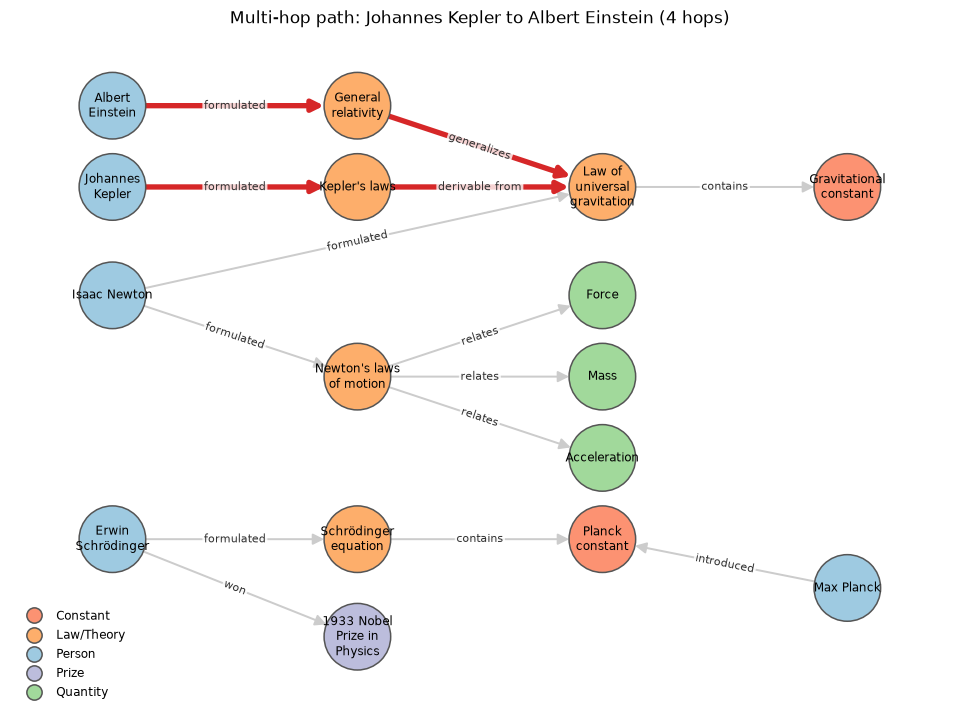

In [4]:
# Path: how is Kepler connected to Einstein? Search the undirected view, then read directions back.
path = nx.shortest_path(G.to_undirected(), "Johannes Kepler", "Albert Einstein")
for a, b in zip(path, path[1:]):
    if G.has_edge(a, b):
        print(f"  {a} --{G[a][b]['relation']}--> {b}")
    else:
        print(f"  {a} <--{G[b][a]['relation']}-- {b}")

draw_kg(G, title="Multi-hop path: Johannes Kepler to Albert Einstein (4 hops)", path=path, k=1.1);

## 3. Schema: the shape of the graph

Collapse every node into its type and you get the **schema** (or *ontology*): which types connect to
which, through which relations. A curated KG (Wikidata, a company product graph) fixes the schema up
front. A KG extracted by an LLM usually has *no* fixed schema: the relation labels are whatever the model
wrote, which is one reason such graphs get messy (Section 8).

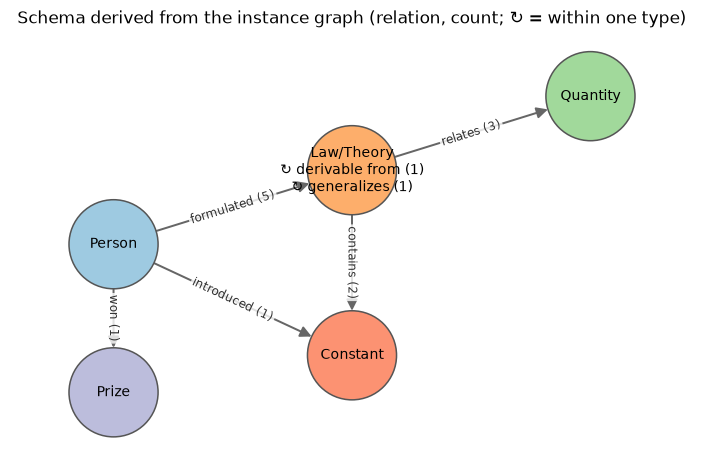

In [5]:
schema = nx.DiGraph()
counts = Counter((G.nodes[h]["type"], r, G.nodes[t]["type"]) for h, t, r in G.edges(data="relation"))
for (ht, r, tt), n in counts.items():
    if ht == tt:                                 # relation within one type: note it on the node
        schema.add_node(ht)
        schema.nodes[ht]["note"] = (schema.nodes[ht].get("note", "") + f"\n↻ {r} ({n})").strip()
        continue
    label = f"{r} ({n})"
    if schema.has_edge(ht, tt):                 # several relations between the same pair of types
        label = schema[ht][tt]["relation"] + "\n" + label
    schema.add_edge(ht, tt, relation=label)
for n in schema:
    schema.nodes[n]["type"] = n

fig, ax = plt.subplots(figsize=(8, 5))
draw_kg(schema, ax=ax, pos={"Person": (0, 0), "Law/Theory": (3, 1), "Quantity": (6, 2),
                            "Constant": (3, -1.5), "Prize": (0, -2)}, title="Schema derived from the instance graph (relation, count; ↻ = within one type)",
        node_size=3400, font_size=9, legend=False);
ax.margins(0.15)

## 4. Building a KG from text

Real KGs are rarely typed in by hand. Systems such as **LightRAG** and **HippoRAG** ask an LLM to read
each passage and list `(head, relation, tail)` triples. Below, a few regular expressions stand in for the
LLM so the notebook stays self-contained. The failure modes are the same in kind.

Each triple keeps its **source passage ID**. That is *provenance*: any fact the graph supplies can be
traced back to the text it came from.

In [6]:
passages = {
    "P1": "Isaac Newton formulated the law of universal gravitation. The law of universal gravitation contains the gravitational constant.",
    "P2": "Newton formulated Newton's laws of motion. Newton's laws of motion relate force, mass and acceleration.",
    "P3": "The Schrödinger equation was formulated by Erwin Schrödinger. The Schrödinger equation contains the Planck constant.",
    "P4": "Schrödinger won the 1933 Nobel Prize in Physics. Max Planck won the 1918 Nobel Prize in Physics.",
    "P5": "General relativity, formulated by Albert Einstein, generalizes Newton's law of gravitation.",
    "P6": "The newton is the SI unit of force.",
}

clean = lambda s: re.sub(r"^(the|The) ", "", s.strip())
RULES = [   # (pattern, function from match -> list of (head, relation, tail))
    (r"^(?P<a>[^,]+), formulated by (?P<p>[^,]+), (?P<r>\w+) (?P<t>.+)$",
     lambda m: [(m["p"], "formulated", m["a"]), (m["a"], m["r"], m["t"])]),
    (r"^(?P<t>.+?) was (?P<r>formulated|introduced) by (?P<h>.+)$", lambda m: [(m["h"], m["r"], m["t"])]),
    (r"^(?P<h>.+?) relate (?P<t>.+)$",
     lambda m: [(m["h"], "relates", x) for x in re.split(r",\s*|\s+and\s+", m["t"])]),
    (r"^(?P<h>.+?) is the SI unit of (?P<t>.+)$", lambda m: [(m["h"], "unit of", m["t"])]),
    (r"^(?P<h>.+?) (?P<r>formulated|contains|introduced|won|generalizes) (?P<t>.+)$",
     lambda m: [(m["h"], m["r"], m["t"])]),
]


def extract(text):
    out = []
    for sent in re.split(r"(?<=\.)\s+", text):
        sent = sent.rstrip(".")
        for pat, make in RULES:
            m = re.match(pat, sent)
            if m:
                out += [(clean(h), r, clean(t)) for h, r, t in make(m)]
                break
    return out


raw = [(h, r, t, pid) for pid, text in passages.items() for h, r, t in extract(text)]
for h, r, t, pid in raw:
    print(f"[{pid}] ({h}, {r}, {t})")

G_raw = nx.DiGraph()
for h, r, t, pid in raw:
    G_raw.add_edge(h, t, relation=r, source=pid)
print(f"\n{G_raw.number_of_nodes()} nodes, {G_raw.number_of_edges()} edges, "
      f"{nx.number_weakly_connected_components(G_raw)} connected pieces")

[P1] (Isaac Newton, formulated, law of universal gravitation)
[P1] (law of universal gravitation, contains, gravitational constant)
[P2] (Newton, formulated, Newton's laws of motion)
[P2] (Newton's laws of motion, relates, force)
[P2] (Newton's laws of motion, relates, mass)
[P2] (Newton's laws of motion, relates, acceleration)
[P3] (Erwin Schrödinger, formulated, Schrödinger equation)
[P3] (Schrödinger equation, contains, Planck constant)
[P4] (Schrödinger, won, 1933 Nobel Prize in Physics)
[P4] (Max Planck, won, 1918 Nobel Prize in Physics)
[P5] (Albert Einstein, formulated, General relativity)
[P5] (General relativity, generalizes, Newton's law of gravitation)
[P6] (newton, unit of, force)

19 nodes, 13 edges, 6 connected pieces


Look at the node list before drawing. The same real-world thing appears under several names:

* `Isaac Newton` and `Newton`
* `Erwin Schrödinger` and `Schrödinger`
* `law of universal gravitation` and `Newton's law of gravitation`

And one name means two different things: `newton` (the unit of force) is not `Newton` (the person).
Without fixing this, the graph is split into pieces that should be connected. With careless fixing, it
asserts false facts.

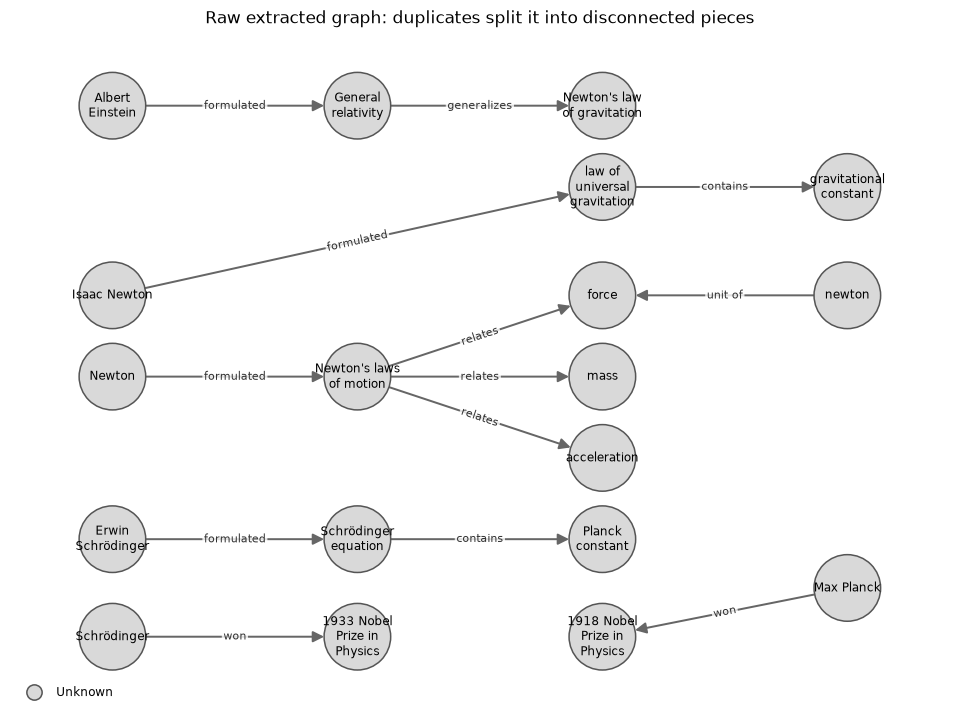

In [7]:
draw_kg(G_raw, title="Raw extracted graph: duplicates split it into disconnected pieces", k=1.3, seed=2);

## 5. Entity resolution: merging duplicates

**Entity resolution** (also *deduplication* or *canonicalization*) maps every surface name to one
canonical node. Two quick rules first:

* **Naive:** lower-case everything, and merge a one-word name into any longer name ending in that word
  (`Newton` → `Isaac Newton`).
* **Careful:** the same surname rule, but case-sensitive, plus an alias table for paraphrases the rule
  cannot see (`Newton's law of gravitation` → `law of universal gravitation`).

Real systems use embedding similarity of the names, sometimes with an LLM check. That catches
paraphrases, but it can make the same kind of wrong merge, so it needs a threshold someone has checked.

In [8]:
def resolve(names, case_sensitive=True, aliases=None):
    key = (lambda s: s) if case_sensitive else str.lower
    mapping = {}
    for a in names:
        if aliases and a in aliases:
            mapping[a] = aliases[a]
            continue
        if " " not in a:     # one-word name: merge into a longer name that ends in it
            hits = [b for b in names if b != a and " " in b and key(b).split()[-1] == key(a)]
            if len(hits) == 1:
                mapping[a] = hits[0]
    return mapping


def relabel(G, mapping):
    return nx.relabel_nodes(G, lambda n: mapping.get(n, n), copy=True)


naive = resolve(list(G_raw), case_sensitive=False)
careful = resolve(list(G_raw), case_sensitive=True,
                  aliases={"Newton's law of gravitation": "law of universal gravitation"})
print("naive merges:  ", naive)
print("careful merges:", careful)

G_naive, G_res = relabel(G_raw, naive), relabel(G_raw, careful)
print("\nFalse fact created by the naive merge:",
      [(h, r, t) for h, t, r in G_naive.edges(data="relation") if r == "unit of"])

naive merges:   {'Newton': 'Isaac Newton', 'Schrödinger': 'Erwin Schrödinger', 'newton': 'Isaac Newton'}
careful merges: {'Newton': 'Isaac Newton', 'Schrödinger': 'Erwin Schrödinger', "Newton's law of gravitation": 'law of universal gravitation'}

False fact created by the naive merge: [('Isaac Newton', 'unit of', 'force')]


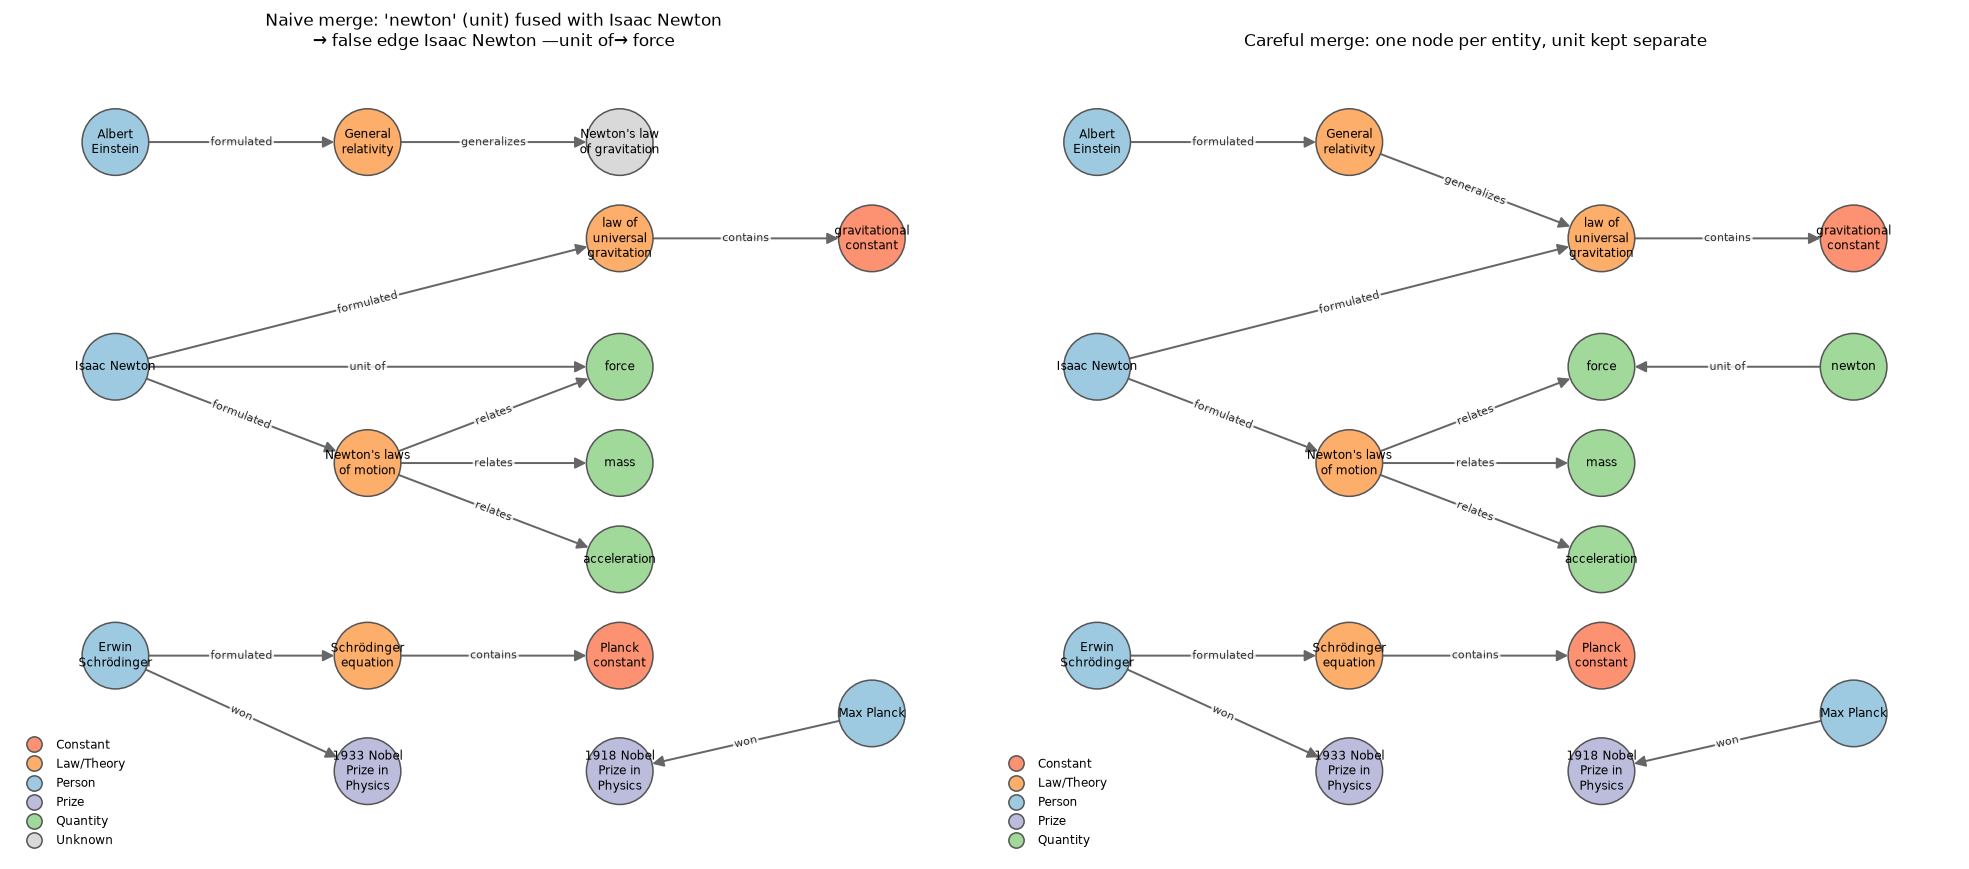

In [9]:
TYPES2 = {"Isaac Newton": "Person", "Erwin Schrödinger": "Person", "Albert Einstein": "Person",
          "Max Planck": "Person", "law of universal gravitation": "Law/Theory",
          "Newton's laws of motion": "Law/Theory", "Schrödinger equation": "Law/Theory",
          "General relativity": "Law/Theory", "force": "Quantity", "mass": "Quantity",
          "acceleration": "Quantity", "gravitational constant": "Constant", "Planck constant": "Constant",
          "1933 Nobel Prize in Physics": "Prize", "1918 Nobel Prize in Physics": "Prize", "newton": "Quantity"}
for g in (G_naive, G_res):
    for n in g:
        g.nodes[n]["type"] = TYPES2.get(n, "Unknown")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
draw_kg(G_naive, ax=axes[0], seed=4, k=1.2,
        title="Naive merge: 'newton' (unit) fused with Isaac Newton\n→ false edge Isaac Newton —unit of→ force")
draw_kg(G_res, ax=axes[1], seed=4, k=1.2,
        title="Careful merge: one node per entity, unit kept separate")
plt.tight_layout()

## 6. Multi-hop question answering, with provenance

> *Which constant appears in the equation formulated by the winner of the 1933 Nobel Prize in Physics?*

No single passage answers this. P4 says who won the 1933 prize; P3 says what that person's equation
contains. P3 never mentions the prize, so it shares few words with the question. That's the classic
case for a graph: the **bridge entity** (Schrödinger) links the two facts.

First, plain keyword retrieval: rank passages by how many question words they contain.

In [10]:
question = "Which constant appears in the equation formulated by the winner of the 1933 Nobel Prize in Physics?"
STOP = {"which", "in", "the", "by", "of", "a", "an"}
words = lambda s: set(re.findall(r"\w+", s.lower())) - STOP

q = words(question)
for pid, text in sorted(passages.items(), key=lambda kv: -len(q & words(kv[1]))):
    print(f"{pid}  overlap={len(q & words(text))}  {sorted(q & words(text))}")

P4  overlap=4  ['1933', 'nobel', 'physics', 'prize']
P3  overlap=3  ['constant', 'equation', 'formulated']
P1  overlap=2  ['constant', 'formulated']
P2  overlap=1  ['formulated']
P5  overlap=1  ['formulated']
P6  overlap=0  []


P4 (the bridge passage) ranks first; P3 (the answer passage) ranks second. With top-1 retrieval the
answer is missed; with top-2 it's found. That's the honest picture: graphs aren't always needed,
since plain retrieval often works if it fetches enough passages. The graph helps most when the second-hop
passage shares few words with the question.

The graph version answers with a short chain of lookups, and every hop carries its source passage:

Answer: Planck constant
  Erwin Schrödinger won the 1933 Nobel Prize   [P4]
  Erwin Schrödinger formulated Schrödinger equation   [P3]
  Schrödinger equation contains Planck constant   [P3]


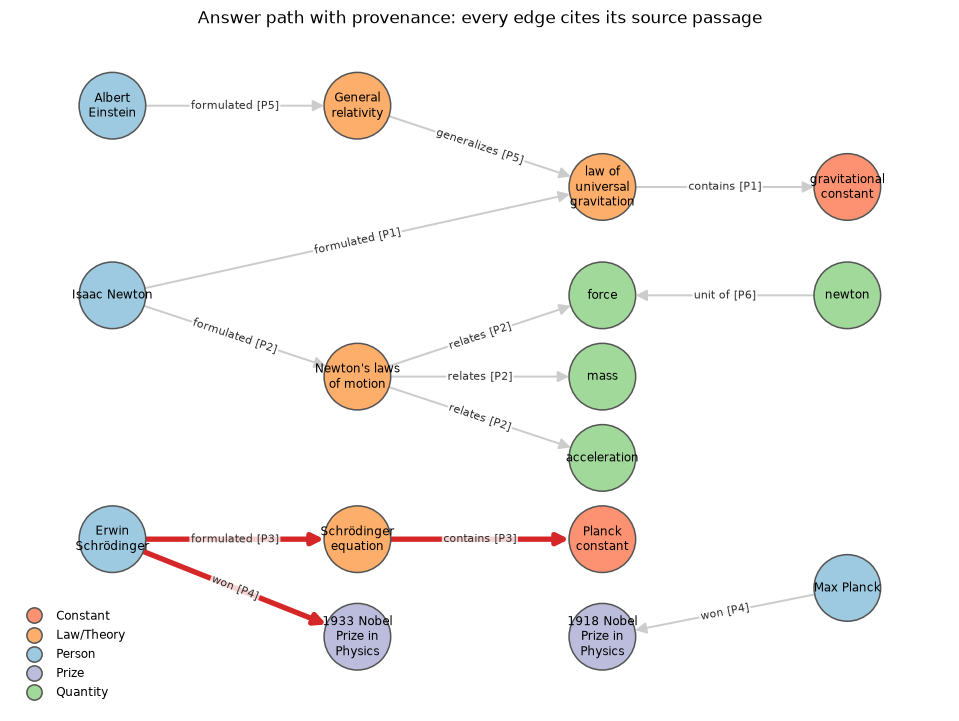

In [11]:
def hop(G, node, relation, reverse=False):
    edges = G.in_edges(node, data=True) if reverse else G.out_edges(node, data=True)
    return [((u if reverse else v), d["source"]) for u, v, d in edges if d["relation"] == relation]

start = "1933 Nobel Prize in Physics"                      # entity linked from the question
for person, s1 in hop(G_res, start, "won", reverse=True):
    for eq, s2 in hop(G_res, person, "formulated"):
        for const, s3 in hop(G_res, eq, "contains"):
            print(f"Answer: {const}")
            print(f"  {person} won the 1933 Nobel Prize   [{s1}]")
            print(f"  {person} formulated {eq}   [{s2}]")
            print(f"  {eq} contains {const}   [{s3}]")
            answer_path = [start, person, eq, const]

for u, v, d in G_res.edges(data=True):
    d["label"] = f"{d['relation']} [{d['source']}]"
draw_kg(G_res, title="Answer path with provenance: every edge cites its source passage",
        path=answer_path, edge_label="label", seed=4, k=1.2);

## 7. Personalized PageRank (the idea behind HippoRAG)

Exact chain queries need the question parsed into relations, which is brittle. **HippoRAG** does
something softer: it marks the entities mentioned in the question as *seeds* and runs
**Personalized PageRank (PPR)**, a random walk that keeps restarting at the seeds. Nodes near the seeds,
especially ones reachable through several routes, collect probability. Passages are then ranked by the
PPR mass of the entities they contain.

seed entities found in the question: ['1933 Nobel Prize in Physics']
  0.358  Erwin Schrödinger
  0.302  1933 Nobel Prize in Physics
  0.238  Schrödinger equation
  0.101  Planck constant
  0.000  Newton's laws of motion
  0.000  law of universal gravitation

passage ranking: [(0.698, 'P3'), (0.66, 'P4'), (0.0, 'P6'), (0.0, 'P5'), (0.0, 'P2'), (0.0, 'P1')]


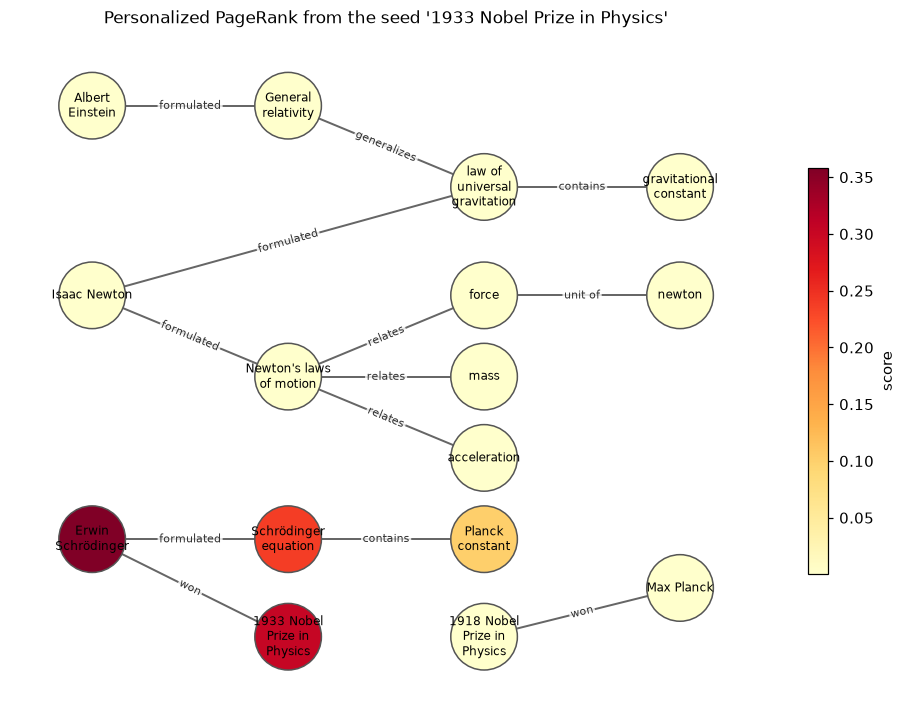

In [12]:
U = G_res.to_undirected()
seeds = {n: 1.0 for n in U if n.lower() in question.lower()}
print("seed entities found in the question:", list(seeds))
ppr = nx.pagerank(U, alpha=0.85, personalization=seeds)

for n, s in sorted(ppr.items(), key=lambda kv: -kv[1])[:6]:
    print(f"  {s:.3f}  {n}")

# Passage score = sum of PPR over the (resolved) entities extracted from it
canon = lambda n: careful.get(n, n)
ents = {pid: {canon(h) for h, _, _, p in raw if p == pid} | {canon(t) for _, _, t, p in raw if p == pid}
        for pid in passages}
print("\npassage ranking:", sorted(((round(sum(ppr[e] for e in es), 3), pid) for pid, es in ents.items()),
                                   reverse=True))

draw_kg(U, values=ppr, edge_label="relation", seed=4, k=1.2,
        title="Personalized PageRank from the seed '1933 Nobel Prize in Physics'");

The answer passage P3 now ranks *first*, just ahead of the bridge passage P4, although it shares
fewer words with the question. The score comes through the graph, not through word overlap. P6 and P2 score near zero: they sit in the Newton part of the graph,
which the random walk can't reach from the seed.

## 8. A real LLM-built graph: structure at scale

Toy graphs are tidy. Here is the graph LightRAG built with Qwen2.5-7B from the first 170 Wikipedia
chunks of this project's corpus (a trial run; the full build has not been done yet). If that file is
not on this machine, a random graph with similar statistics stands in.

What to look for, and why it matters for retrieval:

* **Components:** a graph split into many small pieces can't connect facts across them.
* **Degree distribution:** a few huge hubs (generic entities like "energy") and many nodes with
  one edge. Hubs make random walks and neighbourhood expansion drift.
* **Edges per node:** below about 1, most entities touch at most one fact.

LightRAG trial graph (170 chunks): 2402 nodes, 1651 edges (0.69 edges per node)
components: 958; largest holds 1189 nodes (50%)
degree: median 1, max 101, share with degree 0 or 1: 82%


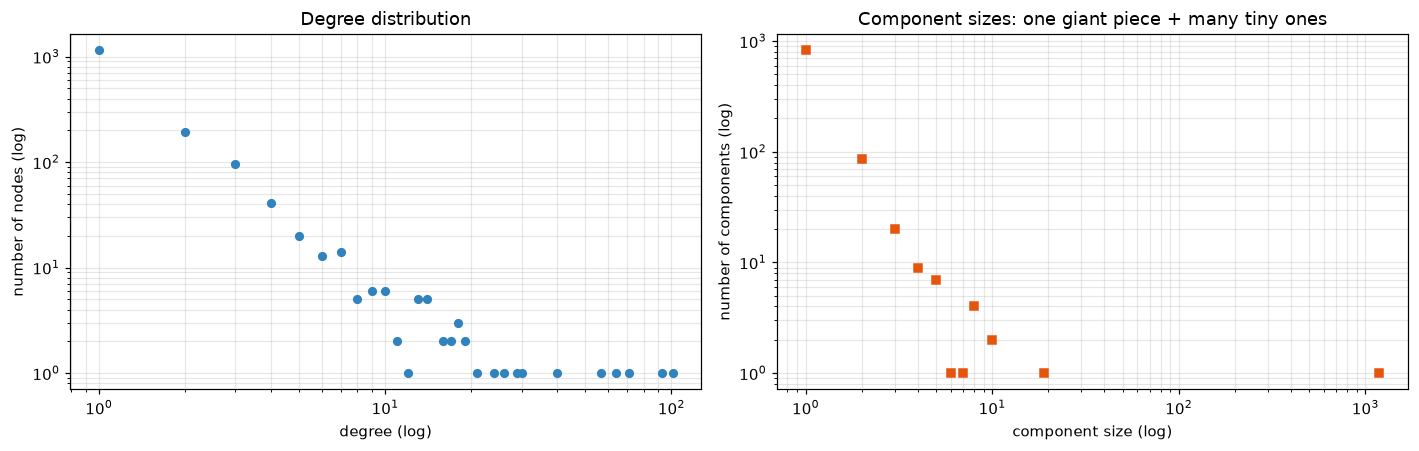

In [13]:
GRAPHML = Path("../data/graphs/lightrag_main/graph_chunk_entity_relation.graphml")
if GRAPHML.exists():
    R = nx.read_graphml(GRAPHML)
    source = "LightRAG trial graph (170 chunks)"
else:
    R = nx.Graph(nx.powerlaw_cluster_graph(2400, 1, 0.1, seed=0).subgraph(range(1200)))
    R.add_nodes_from(range(2400, 3600))             # many isolated pieces, as in extracted graphs
    source = "synthetic stand-in"

comps = sorted((len(c) for c in nx.connected_components(R)), reverse=True)
deg = np.array([d for _, d in R.degree()])
print(f"{source}: {R.number_of_nodes()} nodes, {R.number_of_edges()} edges "
      f"({R.number_of_edges() / R.number_of_nodes():.2f} edges per node)")
print(f"components: {len(comps)}; largest holds {comps[0]} nodes ({comps[0] / R.number_of_nodes():.0%})")
print(f"degree: median {np.median(deg):.0f}, max {deg.max()}, share with degree 0 or 1: {(deg <= 1).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
vals, cnts = np.unique(deg[deg > 0], return_counts=True)
axes[0].loglog(vals, cnts, "o", color="#3182bd", ms=5)
axes[0].set(xlabel="degree (log)", ylabel="number of nodes (log)", title="Degree distribution")
sizes, scnt = np.unique(comps, return_counts=True)
axes[1].loglog(sizes, scnt, "s", color="#e6550d", ms=5)
axes[1].set(xlabel="component size (log)", ylabel="number of components (log)",
            title="Component sizes: one giant piece + many tiny ones")
for a in axes:
    a.grid(alpha=0.3, which="both")
plt.tight_layout()

hub = 'DeBroglieBohmTheory' with degree 101; showing 20 of its neighbours


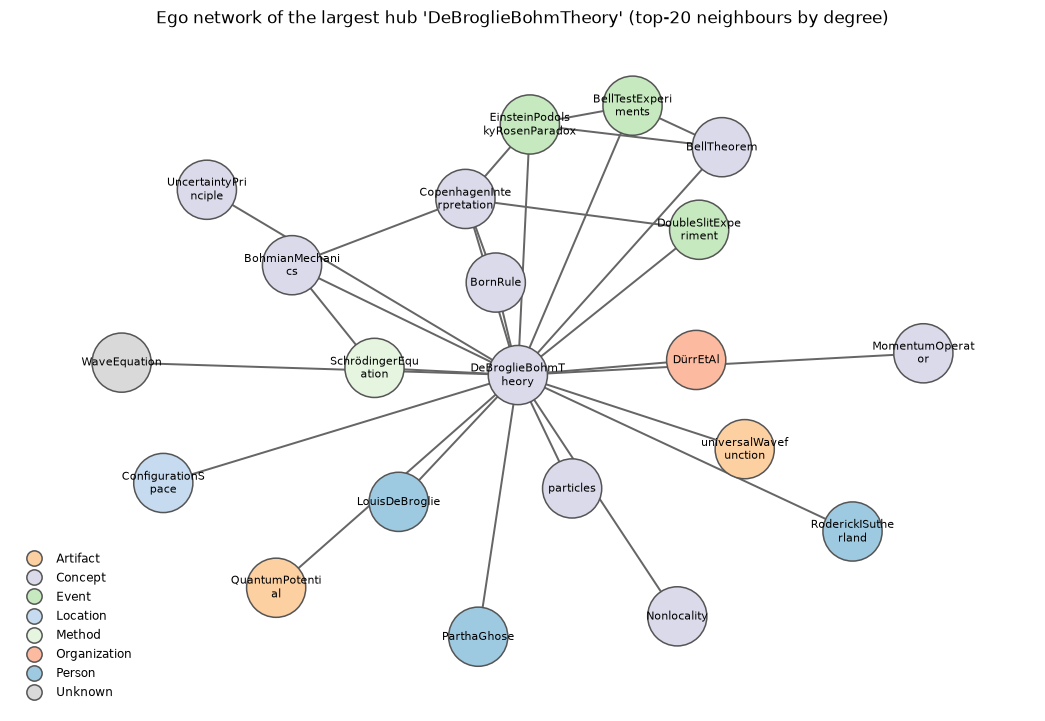

In [14]:
# The biggest hub and its 20 best-connected neighbours
hub = max(R.degree(), key=lambda kv: kv[1])[0]
nbrs = sorted(R[hub], key=lambda n: -R.degree(n))[:20]
E = R.subgraph([hub] + nbrs).copy()
for n in E:
    E.nodes[n]["type"] = str(R.nodes[n].get("entity_type", "Unknown")).split(",")[0].title() or "Unknown"
    E.nodes[n]["type"] = E.nodes[n]["type"][:18]
print(f"hub = {hub!r} with degree {R.degree(hub)}; showing 20 of its neighbours")

fig, ax = plt.subplots(figsize=(12, 8))
draw_kg(E, ax=ax, edge_label=None, seed=1, node_size=1500, font_size=7,
        title=f"Ego network of the largest hub '{hub}' (top-20 neighbours by degree)");

Look at the node names: `DeBroglieBohmTheory`, `RoderickISutherland`. In this graph 55% of entity names
came out CamelCase-joined, while others keep their spaces (`LiftToDragRatio` next to `Lift/Drag Ratio`).
So the same concept can appear twice in different spellings, the Section 5 problem at scale. Any
evaluation that matches gold answers to node names has to normalise this first.

## Takeaways

* A KG is a set of `(head, relation, tail)` triples. The graph view makes **multi-hop** connections
  explicit and every edge can cite its **source passage**.
* Querying ranges from exact patterns (precise but brittle) to **Personalized PageRank** (soft and
  robust, as in HippoRAG).
* Building a KG automatically is the hard part. Expect **duplicate entities**, **wrong merges**,
  **free-form relation labels**, and a **fragmented** graph with hubs and many one-edge nodes.
* Graphs help most when the evidence for the second hop shares little vocabulary with the question.
  Otherwise plain retrieval with a few more passages often works. Whether the extra cost of building a
  graph pays off is exactly what this project measures: see `RESEARCH_PROPOSAL.md` and `report/`.

**Further reading:** Hogan et al., *Knowledge Graphs* (ACM Computing Surveys, 2021); Edge et al.,
*From Local to Global: A Graph RAG Approach* (Microsoft GraphRAG, 2024); Guo et al., *LightRAG* (2024);
Gutiérrez et al., *HippoRAG* (NeurIPS 2024) and *From RAG to Memory* (HippoRAG 2, 2025).